# Math 465 Fall 2026

## Module 5. Demo: Random matrices and random graphs

Xiuyuan Cheng  
xiuyuan.cheng@duke.edu

This notebook demonstrates:

- the spectrum of Gaussian Wigner matrices and its $\sqrt n$ scale;
- centering and normalizing Erdős–Rényi adjacency matrices.

These examples accompany Lecture 3 and conclude Module 5.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(2026)


### Example 1. Gaussian Wigner matrices

A Wigner matrix is symmetric. Here its entries on and above the diagonal are independent $\mathcal{N}(0,1)$ variables.

After normalization by $\sqrt n$, the empirical eigenvalue distribution approaches
$$
\rho_{\mathrm{sc}}(x)=\frac{1}{2\pi}\sqrt{4-x^2},\qquad |x|\leq2,
$$
with density zero outside this interval. The curve below is the theoretical limiting density, not a fit to the histogram.

In [2]:
def generate_wigner(n):
    U = np.triu(np.random.randn(n, n))
    W = U + U.T - np.diag(np.diag(U))
    return W

def semicircle_density(x):
    y = np.zeros_like(x, dtype=float)
    mask = np.abs(x) <= 2
    y[mask] = np.sqrt(4 - x[mask]**2) / (2*np.pi)
    return y


#### Generate a small Wigner matrix


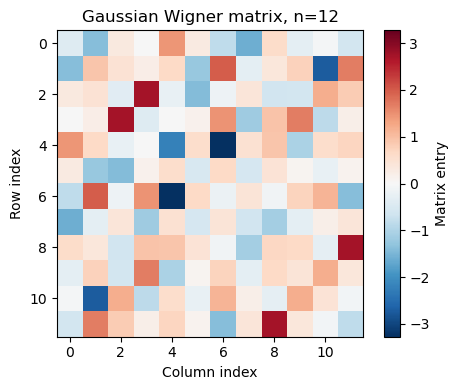

In [3]:
# One small realization
np.random.seed(2026)
W = generate_wigner(12)

fig, ax = plt.subplots(figsize=(5, 4))
limit = np.abs(W).max()
im = ax.imshow(W, cmap='RdBu_r', vmin=-limit, vmax=limit)
fig.colorbar(im, ax=ax, label='Matrix entry')
ax.set(xlabel='Column index', ylabel='Row index', title='Gaussian Wigner matrix, n=12')
fig.tight_layout()
plt.show()


#### Compare normalized spectra as the matrix size increases


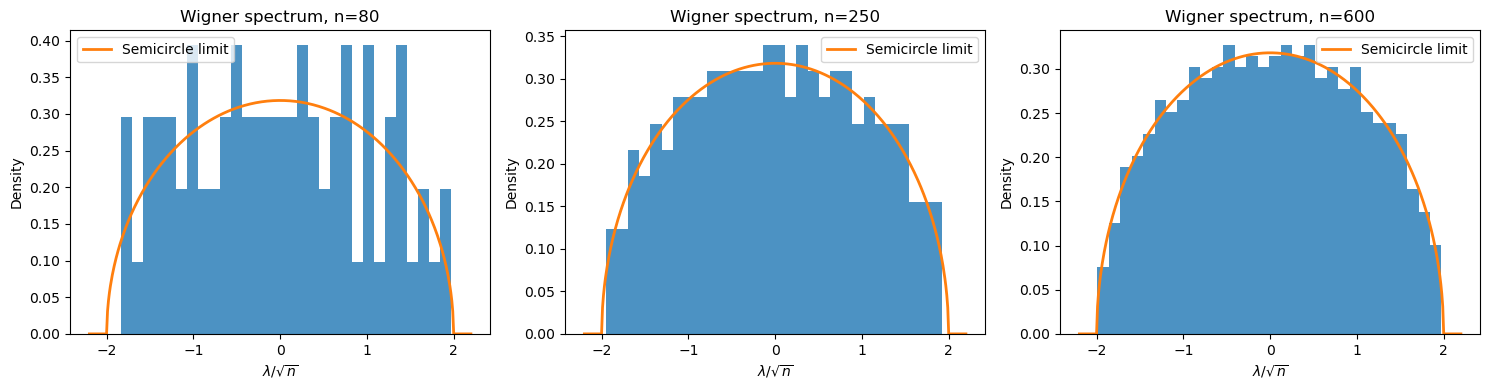

In [4]:
# Semicircle behavior as n increases
np.random.seed(2026)
n_list = [80, 250, 600]
x_grid = np.linspace(-2.2, 2.2, 400)

plt.figure(figsize=(15, 4))
for j, n in enumerate(n_list, start=1):
    W = generate_wigner(n)
    evals = np.linalg.eigvalsh(W) / np.sqrt(n)
    plt.subplot(1, 3, j)
    plt.hist(evals, bins=30, density=True, alpha=0.8)
    plt.plot(x_grid, semicircle_density(x_grid), linewidth=2, label='Semicircle limit')
    plt.xlabel(r'$\lambda/\sqrt{n}$')
    plt.ylabel('Density')
    plt.title(f'Wigner spectrum, n={n}')
    plt.legend()
plt.tight_layout()
plt.show()


The bulk spectrum stabilizes after the $1/\sqrt n$ normalization. In the Gaussian Wigner case, the extreme eigenvalues also approach the edges near $\pm 2$.

### Example 2. Centered Erdős–Rényi adjacency

For an undirected $G(n,p)$ graph without self-loops, $A_{ji}=A_{ij}$, $A_{ii}=0$, and the upper-triangular entries are independent:

$$
A_{ij}\sim \mathrm{Bernoulli}(p),\qquad i<j.
$$

The population adjacency is

$$
\mathbb E A=p(\mathbf 1\mathbf 1^T-I).
$$

After centering,

$$
A_0=A-\mathbb E A,
$$

the off-diagonal entries have mean zero and variance $p(1-p)$. The natural spectral normalization is therefore $\sqrt{np(1-p)}$.

In [5]:
def generate_erdos_renyi(n, p):
    upper = np.triu((np.random.rand(n, n) < p).astype(float), 1)
    return upper + upper.T

def er_mean_matrix(n, p):
    return p * (np.ones((n, n)) - np.eye(n))


#### Generate and center the adjacency matrix


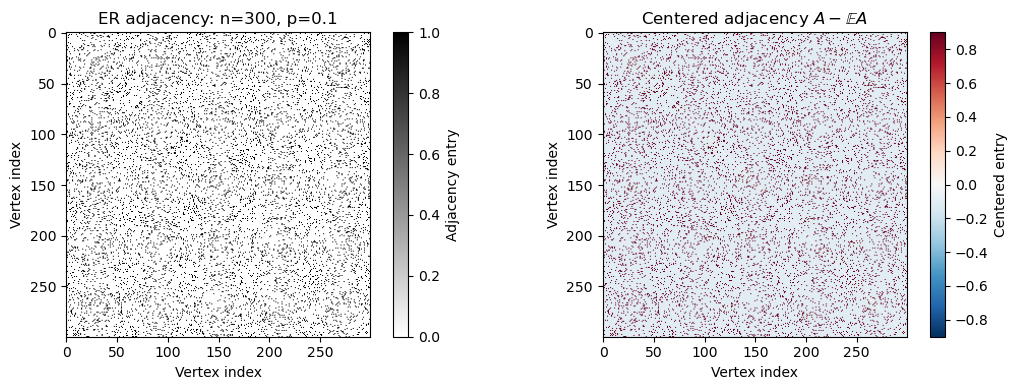

In [6]:
np.random.seed(2027)
n, p = 300, 0.10
A = generate_erdos_renyi(n, p)
A_mean = er_mean_matrix(n, p)
A0 = A - A_mean

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
im = axes[0].imshow(A, cmap='gray_r', vmin=0, vmax=1)
fig.colorbar(im, ax=axes[0], label='Adjacency entry')
axes[0].set_title(f'ER adjacency: n={n}, p={p}')
limit = np.abs(A0).max()
im = axes[1].imshow(A0, cmap='RdBu_r', vmin=-limit, vmax=limit)
fig.colorbar(im, ax=axes[1], label='Centered entry')
axes[1].set_title(r'Centered adjacency $A-\mathbb{E}A$')
for ax in axes:
    ax.set(xlabel='Vertex index', ylabel='Vertex index')
fig.tight_layout()
plt.show()


#### Compare the normalized spectrum with the semicircle density


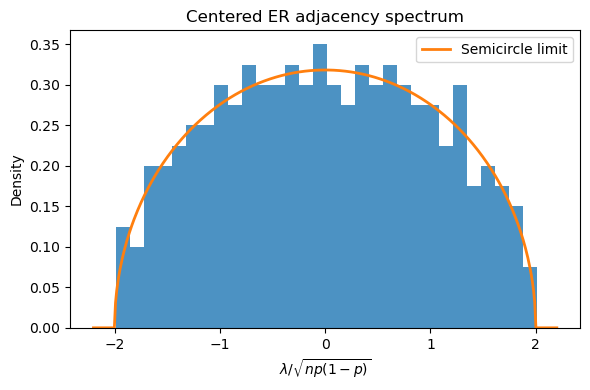

In [7]:
evals0 = np.linalg.eigvalsh(A0) / np.sqrt(n*p*(1-p))

plt.figure(figsize=(6, 4))
plt.hist(evals0, bins=30, density=True, alpha=0.8)
plt.plot(x_grid, semicircle_density(x_grid), linewidth=2, label='Semicircle limit')
plt.xlabel(r'$\lambda / \sqrt{np(1-p)}$')
plt.ylabel('Density')
plt.title('Centered ER adjacency spectrum')
plt.legend()
plt.tight_layout()
plt.show()


Centering removes the population mean structure. Dividing by $\sqrt{np(1-p)}$ puts the eigenvalues on an order-one scale. The semicircle limit applies for fixed $0<p<1$ as $n$ increases; this example uses $p=0.10$.

#### Interpretation questions

- Why is the Frobenius norm of a Wigner matrix of order $n$, while its operator norm is only of order $\sqrt n$?
- Why do we center the ER adjacency matrix before comparing its spectrum with the semicircle density?
- Where does the normalization $\sqrt{np(1-p)}$ come from?
